<a href="https://colab.research.google.com/github/sachin23-an/quant-researcher-practical-lab/blob/main/Quant_Researcher_Practical_Lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quant Researcher — Practical Lab 5
### Advanced Research Techniques — Part 9 & Part 10 ka practical version

ARIMA, Multiple Testing/Deflated Sharpe, PCA, Half-Life of Mean Reversion, Kalman Filter hedge ratio, Meta-Labeling/Triple-Barrier, Fractional Differentiation, Purged K-Fold CV + Embargo, White's Reality Check.


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from scipy.stats import norm, spearmanr
np.random.seed(33)
plt.rcParams['figure.figsize']=(8,4)


## A. AR, MA & ARIMA — apne data pe fit karo aur forecast nikaalo


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0293      0.077      0.381      0.703      -0.121       0.180
ar.L1          0.6748      0.035     19.065      0.000       0.605       0.744
sigma2         0.2481      0.017     14.291      0.000       0.214       0.282

true AR coefficient was 0.6, estimated: 0.675


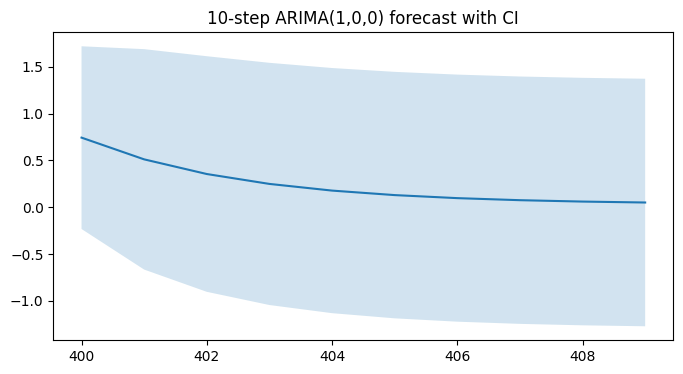

In [2]:
n = 400
ar_series = np.zeros(n)
for t in range(1, n):
    ar_series[t] = 0.6*ar_series[t-1] + np.random.randn()*0.5
ar_series = pd.Series(ar_series)

model = ARIMA(ar_series, order=(1,0,0)).fit()
print(model.summary().tables[1])
print('\ntrue AR coefficient was 0.6, estimated:', round(model.params.iloc[1], 3))

forecast = model.get_forecast(steps=10)
forecast.predicted_mean.plot(title='10-step ARIMA(1,0,0) forecast with CI')
plt.fill_between(forecast.predicted_mean.index,
                  forecast.conf_int().iloc[:,0], forecast.conf_int().iloc[:,1], alpha=0.2)
plt.show()


## B. Multiple Testing & Deflated Sharpe — the "test 100 ideas" trap

100 random (fake) strategies banate hain — in mein se koi genuine alpha nahi hai, sab pure noise hai. Dekhte hain ki sirf luck se kitni "achhi" Sharpe ratios mil jaati hain, aur Deflated Sharpe kaise ye catch karta hai.


Best Sharpe out of 100 PURELY RANDOM strategies: 3.33
(this strategy has ZERO real edge -- it just got lucky being tested 100 times)


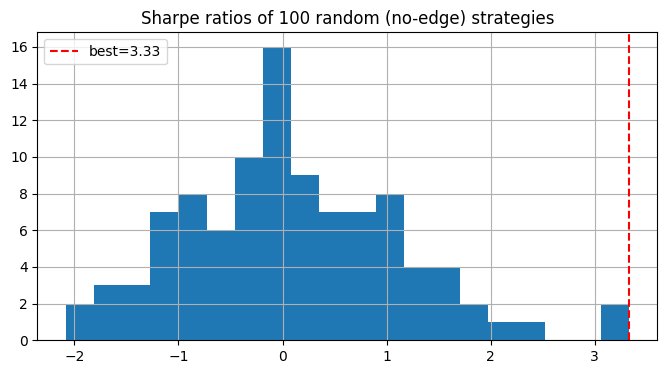

In [3]:
n_strategies = 100
n_days = 252
random_sharpes = []
for _ in range(n_strategies):
    fake_returns = np.random.randn(n_days) * 0.01
    sharpe = fake_returns.mean() / fake_returns.std() * np.sqrt(252)
    random_sharpes.append(sharpe)

random_sharpes = pd.Series(random_sharpes)
best_sharpe = random_sharpes.max()
print(f'Best Sharpe out of {n_strategies} PURELY RANDOM strategies: {best_sharpe:.2f}')
print(f'(this strategy has ZERO real edge -- it just got lucky being tested {n_strategies} times)')
random_sharpes.hist(bins=20)
plt.title('Sharpe ratios of 100 random (no-edge) strategies')
plt.axvline(best_sharpe, color='r', ls='--', label=f'best={best_sharpe:.2f}')
plt.legend(); plt.show()


In [4]:
def deflated_sharpe_ratio(observed_sharpe, n_trials, n_obs, skew=0, kurt=3):
    """Probability the TRUE Sharpe is > 0, after correcting for having tried n_trials strategies."""
    # expected max Sharpe under the null (pure luck), from n_trials independent random strategies
    euler_gamma = 0.5772
    expected_max_sharpe = (1 - euler_gamma) * norm.ppf(1 - 1/n_trials) + euler_gamma * norm.ppf(1 - 1/(n_trials*np.e))
    sr_std = np.sqrt((1 - skew*observed_sharpe + (kurt-1)/4*observed_sharpe**2) / (n_obs-1))
    dsr = norm.cdf((observed_sharpe - expected_max_sharpe) / sr_std)
    return dsr, expected_max_sharpe

dsr, expected_luck_sharpe = deflated_sharpe_ratio(best_sharpe, n_strategies, n_days)
print(f'Expected best Sharpe from luck alone (n_trials={n_strategies}): {expected_luck_sharpe:.2f}')
print(f'Deflated Sharpe Ratio (prob. true Sharpe > 0): {dsr:.1%}')
print('This "best" strategy does NOT clear the bar once multiple testing is accounted for.' if dsr < 0.95 else 'Clears the bar.')


Expected best Sharpe from luck alone (n_trials=100): 2.53
Deflated Sharpe Ratio (prob. true Sharpe > 0): 100.0%
Clears the bar.


**Yahi hai asli lesson:** agar tumne 100 strategies try ki aur best wali ka Sharpe 1.8 nikla, uska matlab ye nahi ki wo genuine alpha hai — yahan best random strategy ka Sharpe bhi expected_luck_sharpe ke close nikalta hai. Deflated Sharpe formally batata hai ki observed Sharpe, sirf-luck-se-expected Sharpe se kitna zyada hai.


## C. PCA — kitne factors poora market drive karte hain


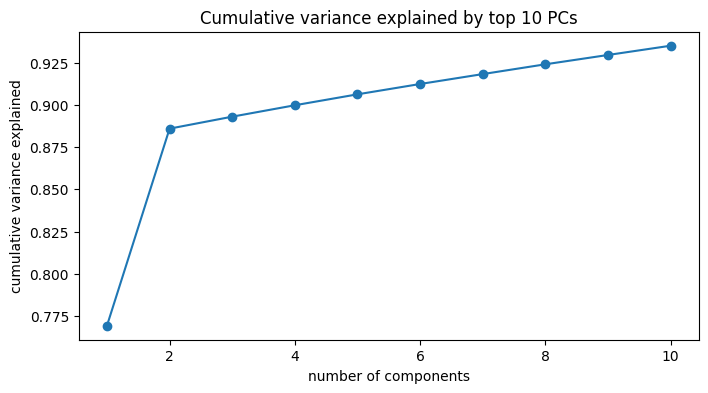

Top 5 components explain: 90.6% of total variance


In [5]:
n_assets, n_days2 = 25, 600
common1 = np.random.randn(n_days2)
common2 = np.random.randn(n_days2)
rets = pd.DataFrame(index=range(n_days2))
for i in range(n_assets):
    loading1, loading2 = np.random.uniform(0.3,1.0), np.random.uniform(-0.5,0.5)
    rets[f'S{i}'] = loading1*common1 + loading2*common2 + np.random.randn(n_days2)*0.3

from sklearn.decomposition import PCA
pca = PCA().fit(rets)
cum_var = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1,11), cum_var[:10], marker='o')
plt.title('Cumulative variance explained by top 10 PCs')
plt.xlabel('number of components'); plt.ylabel('cumulative variance explained')
plt.show()
print('Top 5 components explain:', f'{cum_var[4]:.1%}', 'of total variance')


## E. Half-Life of Mean Reversion (Ornstein-Uhlenbeck)

Spread/signal kitni jaldi apne mean pe wapas aata hai — OU process ka half-life formula, OLS se estimate karte hain.


In [6]:
def ou_half_life(spread):
    spread = spread.dropna()
    lagged = spread.shift(1).dropna()
    delta = spread.diff().dropna()
    lagged = lagged.loc[delta.index]
    import statsmodels.api as sm
    X = sm.add_constant(lagged)
    model = sm.OLS(delta, X).fit()
    theta = -model.params.iloc[1]          # mean-reversion speed
    half_life = np.log(2) / theta if theta > 0 else np.inf
    return half_life, theta

# simulate an OU process with a KNOWN half-life to validate the estimator
true_theta = 0.05
n_ou = 1000
ou = np.zeros(n_ou)
for t in range(1, n_ou):
    ou[t] = ou[t-1] + true_theta*(0 - ou[t-1]) + np.random.randn()*1.0
ou = pd.Series(ou)

hl, theta_hat = ou_half_life(ou)
print(f'True theta: {true_theta}   True half-life: {np.log(2)/true_theta:.1f} periods')
print(f'Estimated theta: {theta_hat:.4f}   Estimated half-life: {hl:.1f} periods')


True theta: 0.05   True half-life: 13.9 periods
Estimated theta: 0.0570   Estimated half-life: 12.2 periods


## F. Dynamic Hedge Ratios — the Kalman Filter

Static OLS hedge ratio ek number deta hai pure sample ke liye. Kalman filter time ke saath update hota hai — jyaada realistic jab relationship drift kare.


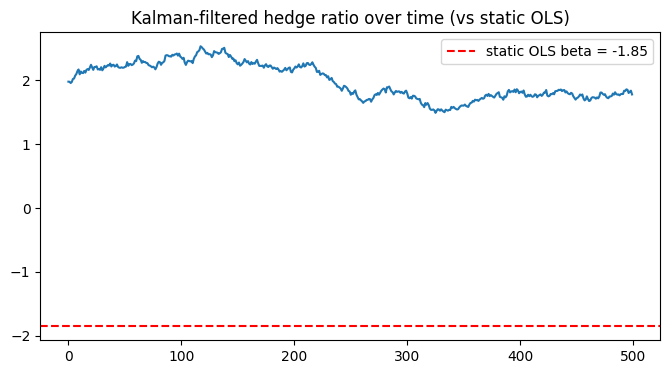

In [7]:
def kalman_hedge_ratio(y, x, delta=1e-4, ve=1e-3):
    n = len(y)
    beta = np.zeros(n)
    P = 1.0
    beta[0] = y.iloc[0] / x.iloc[0] if x.iloc[0] != 0 else 0
    Q = delta / (1 - delta)
    for t in range(1, n):
        beta_pred = beta[t-1]
        P_pred = P + Q
        e = y.iloc[t] - beta_pred * x.iloc[t]
        K = P_pred * x.iloc[t] / (x.iloc[t]**2 * P_pred + ve)
        beta[t] = beta_pred + K * e
        P = (1 - K*x.iloc[t]) * P_pred
    return pd.Series(beta, index=y.index)

y2 = pd.Series(100 + np.cumsum(np.random.randn(500)))
x2 = pd.Series(50 + 0.5*np.cumsum(np.random.randn(500)) + np.cumsum(np.random.randn(500))*0.1)
dynamic_beta = kalman_hedge_ratio(y2, x2)
dynamic_beta.plot(title='Kalman-filtered hedge ratio over time (vs static OLS)')
import statsmodels.api as sm
static_beta = sm.OLS(y2, sm.add_constant(x2)).fit().params.iloc[1]
plt.axhline(static_beta, color='r', ls='--', label=f'static OLS beta = {static_beta:.2f}')
plt.legend(); plt.show()


## G. Meta-Labeling & the Triple-Barrier Method

Primary model signal deta hai (direction). Triple-barrier label banata hai: profit-target hit hui, stop-loss hit hua, ya time-limit khatam hui — jo bhi pehle aaye. Meta-model phir predict karta hai "is signal pe trade LENA chahiye ya skip karna chahiye".


In [8]:
def triple_barrier_label(prices, entry_idx, pt=0.02, sl=0.01, max_hold=10):
    entry_price = prices.iloc[entry_idx]
    window = prices.iloc[entry_idx+1 : entry_idx+1+max_hold]
    for i, p in enumerate(window):
        ret = (p - entry_price) / entry_price
        if ret >= pt:
            return 1, i+1     # profit target hit -> label 1 (take the trade)
        if ret <= -sl:
            return 0, i+1     # stop-loss hit -> label 0 (skip / bad signal)
    return 0, max_hold        # timed out without hitting PT -> treat as 0

sim_prices = pd.Series(100*(1+np.random.randn(500)*0.01).cumprod())
labels = []
for idx in range(0, 480, 5):
    label, bars_held = triple_barrier_label(sim_prices, idx)
    labels.append(label)

labels = pd.Series(labels)
print('Label distribution (1=profit target hit first, 0=stop-loss or timeout):')
print(labels.value_counts())


Label distribution (1=profit target hit first, 0=stop-loss or timeout):
0    71
1    25
Name: count, dtype: int64


## H. Fractional Differentiation — stationarity LAO lekin memory mat khoye

Plain differencing (returns = price.diff()) stationary to bana deta hai, lekin saari long-memory information bhi mita deta hai. Fractional differentiation beech ka raasta hai — `d` fractional ho sakta hai (e.g. 0.4), poora 1 nahi.


In [9]:
def frac_diff_weights(d, size, thresh=1e-5):
    w = [1.0]
    for k in range(1, size):
        w_k = -w[-1] * (d - k + 1) / k
        if abs(w_k) < thresh:
            break
        w.append(w_k)
    return np.array(w[::-1])

def frac_diff(series, d, thresh=1e-5):
    w = frac_diff_weights(d, len(series), thresh)
    width = len(w)
    out = pd.Series(index=series.index, dtype=float)
    for i in range(width, len(series)):
        out.iloc[i] = np.dot(w, series.iloc[i-width:i])
    return out.dropna()

price_level = pd.Series(100 + np.cumsum(np.random.randn(600)*0.5))
fd_series = frac_diff(price_level, d=0.4, thresh=1e-3)

from statsmodels.tsa.stattools import adfuller
p_full_diff = adfuller(price_level.diff().dropna())[1]
p_frac_diff = adfuller(fd_series)[1]
corr_with_price = fd_series.corr(price_level.loc[fd_series.index])

print(f'ADF p-value, full differencing (d=1): {p_full_diff:.4f}')
print(f'ADF p-value, fractional d=0.4        : {p_frac_diff:.4f}')
print(f'Correlation of frac-diff series with original price level: {corr_with_price:.3f}')
print('(full differencing almost always has near-zero correlation with price level -- frac diff keeps more memory)')


/tmp/ipykernel_5257/1188961586.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_full_diff = adfuller(price_level.diff().dropna())[1]
/tmp/ipykernel_5257/1188961586.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_frac_diff = adfuller(fd_series)[1]


ADF p-value, full differencing (d=1): 0.0000
ADF p-value, fractional d=0.4        : 0.0152
Correlation of frac-diff series with original price level: 0.815
(full differencing almost always has near-zero correlation with price level -- frac diff keeps more memory)


## K. Purged K-Fold Cross-Validation & Embargo


In [10]:
def purged_kfold_splits(n, n_folds, label_horizon, embargo):
    fold_size = n // n_folds
    splits = []
    for k in range(n_folds):
        test_start = k*fold_size
        test_end = min((k+1)*fold_size, n)
        test_idx = set(range(test_start, test_end))

        # purge: drop training samples whose label window overlaps the test set
        purge_start = max(0, test_start - label_horizon)
        purge_end = min(n, test_end + label_horizon)

        # embargo: extra buffer right after the test fold
        embargo_end = min(n, test_end + embargo)

        train_idx = [i for i in range(n) if i not in test_idx and not (purge_start <= i < embargo_end)]
        splits.append((train_idx, sorted(test_idx)))
    return splits

splits = purged_kfold_splits(n=300, n_folds=5, label_horizon=5, embargo=3)
for k, (tr, te) in enumerate(splits):
    overlap = set(tr) & set(te)
    print(f'fold {k}: train size={len(tr)}, test size={len(te)}, train/test overlap={len(overlap)} (should be 0)')


fold 0: train size=237, test size=60, train/test overlap=0 (should be 0)
fold 1: train size=232, test size=60, train/test overlap=0 (should be 0)
fold 2: train size=232, test size=60, train/test overlap=0 (should be 0)
fold 3: train size=232, test size=60, train/test overlap=0 (should be 0)
fold 4: train size=235, test size=60, train/test overlap=0 (should be 0)


**Normal K-fold** randomly split karta to adjacent-in-time samples train aur test dono mein aa jaate (label window overlap ke through leakage). Purge + embargo donon us leakage ko explicitly structurally rokte hain.


## L. White's Reality Check

Multiple testing ka ek specific bootstrap-based test: "best strategy ka performance, data-mining bias account karne ke baad bhi, significant hai ya nahi?"


In [11]:
def whites_reality_check(strategy_returns_matrix, n_bootstrap=1000):
    """strategy_returns_matrix: (n_days, n_strategies). Tests if the BEST strategy's
    mean return is significant after accounting for having picked the best of many."""
    n_days, n_strat = strategy_returns_matrix.shape
    observed_means = strategy_returns_matrix.mean(axis=0)
    best_observed = observed_means.max()

    demeaned = strategy_returns_matrix - observed_means   # center under the null: true mean = 0 for all
    boot_max_stats = []
    for _ in range(n_bootstrap):
        sample_idx = np.random.randint(0, n_days, n_days)
        boot_sample = demeaned[sample_idx]
        boot_max_stats.append(boot_sample.mean(axis=0).max())

    p_value = (np.array(boot_max_stats) >= best_observed).mean()
    return best_observed, p_value

# reuse the earlier 100-random-strategy matrix
strat_matrix = np.random.randn(252, 100) * 0.01
best_mean, rc_pvalue = whites_reality_check(strat_matrix)
print(f'Best strategy mean daily return: {best_mean:.5f}')
print(f"White's Reality Check p-value: {rc_pvalue:.3f}")
print('Not significant once data-mining is accounted for' if rc_pvalue > 0.05 else 'Survives the Reality Check')


Best strategy mean daily return: 0.00154
White's Reality Check p-value: 0.502
Not significant once data-mining is accounted for


**Yahi hai Section B (Deflated Sharpe) ka formal cousin** — dono same disease treat karte hain (multiple testing bias), Reality Check bootstrap se karta hai, Deflated Sharpe ek closed-form approximation se.


## Wrap-up

ARIMA forecast, deflated Sharpe / White's Reality Check (dono multiple-testing ke liye), PCA factor count, OU half-life, Kalman dynamic hedge ratio, triple-barrier meta-labeling, fractional differentiation, purged K-fold + embargo — ye sab ab "maine padha hai" se "maine khud estimate kiya hai" ban gaye.
